# Reto: clasificación de 3 escenas (bosque, costa y autopista)

Se usa el dataset local de 3 escenas (`coast`, `forest`, `highway`; 961
imágenes) y se comparan, sobre el mismo split y con las mismas métricas, una CNN
secuencial (base y mejorada), una arquitectura **no secuencial** (DenseNet121
preentrenada en ImageNet con fine-tuning), un **Swin Transformer entrenado
desde cero** (la bala de IA generativa del enunciado) y los **modelos de
machine learning** con descriptores HSV+HOG que hacen de línea base del curso.

| Grupo | Modelo | Cuaderno | Resultados |
|---|---|---|---|
| CNN | CNN base y CNN mejorada | `ScenesCNN.ipynb` | `resultados/cnn/` |
| DL no secuencial | DenseNet121 preentrenada + fine-tuning | `ScenesDenseNet.ipynb` | `resultados/densenet/` |
| IA generativa | Swin Transformer entrenado desde cero | `ScenesSWIN.ipynb` | `resultados/swin/` |
| Machine learning | Regresión logística, SVM (RBF) y Random Forest | `ScenesClassicML.ipynb` | `resultados/ml/` |

Al entrenar el Swin **desde cero** (sin ImageNet), la comparación con la
DenseNet121 separa *arquitectura* (atención vs convolución) de
*preentrenamiento* (ImageNet vs desde cero): la sección «El Transformer Swin»
lee los números con el McNemar y los IC 95 % de bootstrap.

## Protocolo

* **Dataset**: 961 imágenes JPG (`coast` 361, `forest` 329, `highway` 271; un
  reparto aproximado de 38/34/28 %), redimensionadas a 128×128 con `INTER_AREA`.
* **Split**: 25 % test y, del 75 % restante, un 15 % para validación (estratificado,
  semilla 20 → ≈ 612 train / 108 validación / 241 test, en `resultados/split.json`). El test no se usa para entrenar ni para early
  stopping, y todos los modelos evalúan exactamente el mismo `test_idx`
  (~240 imágenes).
* **Métricas**: accuracy, precisión/recall/F1 macro y weighted, Cohen's kappa,
  ROC-AUC one-vs-rest, matriz de confusión, IC 95 % por bootstrap (2000
  remuestreos) y test exacto de McNemar.
* **Evidencia**: cada modelo guarda `metrics.json`, `predictions.csv`,
  `classification_report.txt`, `history.csv` (solo modelos con épocas) y el
  modelo entrenado (`model.keras` o `model.joblib`).

## Carga de resultados y tabla resumen

Si `resultados/` todavía no tiene métricas (los cuadernos de los modelos no se
han ejecutado), este cuaderno imprime un aviso y las celdas siguientes se
omiten **sin lanzar ningún error**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import common_3scenes as cs

sns.set_theme(style="whitegrid", context="notebook")
comparison_dir = cs.result_dir("comparacion")
comparison_dir.mkdir(parents=True, exist_ok=True)

order = ["cnn/base", "cnn/mejorada", "densenet", "swin", "ml/logreg", "ml/svm", "ml/rf"]
results = cs.load_all_results()
split_meta = cs.load_split()
predictions = {}

if results.empty:
    HAS_RESULTS = False
    print(
        "[aviso] Todavía no hay resultados en resultados/. Ejecuta antes "
        "ScenesCNN.ipynb, ScenesDenseNet.ipynb, ScenesSWIN.ipynb y "
        "ScenesClassicML.ipynb (o "
        "usa nbconvert como indica el README). Este cuaderno termina aquí sin "
        "error: las celdas siguientes solo se omiten."
    )
else:
    HAS_RESULTS = True
    results["order"] = results["folder"].map(
        {folder: index for index, folder in enumerate(order)}
    )
    results = (
        results.sort_values("order", na_position="last")
        .drop(columns="order")
        .reset_index(drop=True)
    )

    interval_rows = []
    for _, row in results.iterrows():
        frame = cs.load_predictions(row["folder"])
        predictions[row["model"]] = frame
        if frame is None:
            accuracy_low, accuracy_high = np.nan, np.nan
        else:
            accuracy_low, accuracy_high = cs.bootstrap_accuracy_ci(
                frame["true_class"], frame["predicted_class"], n_boot=2000
            )
        interval_rows.append(
            {
                "model": row["model"],
                "accuracy_low": accuracy_low,
                "accuracy_high": accuracy_high,
            }
        )
    results = results.merge(pd.DataFrame(interval_rows), on="model")

    summary_columns = [
        "model",
        "family",
        "accuracy",
        "f1_macro",
        "f1_weighted",
        "precision_macro",
        "recall_macro",
        "cohen_kappa",
        "roc_auc_ovr_macro",
        "parameters",
        "training_seconds",
        "inference_ms_per_image",
        "epochs",
    ]
    summary = results[summary_columns].copy()
    summary.to_csv(comparison_dir / "model_summary.csv", index=False)

    display_summary = summary.rename(
        columns={
            "model": "Modelo",
            "family": "Familia",
            "accuracy": "Accuracy",
            "f1_macro": "F1 macro",
            "f1_weighted": "F1 weighted",
            "precision_macro": "Precisión macro",
            "recall_macro": "Recall macro",
            "cohen_kappa": "Kappa",
            "roc_auc_ovr_macro": "AUC OVR",
            "parameters": "Parámetros",
            "training_seconds": "Entrenamiento (s)",
            "inference_ms_per_image": "Inferencia (ms/img)",
            "epochs": "Épocas",
        }
    )
    display_summary["Familia"] = display_summary["Familia"].replace(
        {"DL (non-sequential)": "DL (no secuencial)"}
    )
    display_summary["Parámetros"] = display_summary["Parámetros"].map(
        lambda value: "—" if pd.isna(value) else f"{int(value):,}"
    )
    display_summary["Entrenamiento (s)"] = display_summary["Entrenamiento (s)"].map(
        lambda value: "—" if pd.isna(value) else f"{value:,.0f}"
    )
    display_summary["Inferencia (ms/img)"] = display_summary["Inferencia (ms/img)"].map(
        lambda value: "—" if pd.isna(value) else f"{value:.1f}"
    )
    display_summary["Épocas"] = display_summary["Épocas"].map(
        lambda value: "—" if pd.isna(value) else f"{int(value)}"
    )

    print(
        f"[ok] {len(results)} modelos cargados de resultados/ | "
        f"test común: {split_meta.get('n_test', 'n/d')} imágenes"
    )
display_summary.round(4) if HAS_RESULTS else None

[ok] 6 modelos cargados de resultados/ | test común: 240 imágenes


,Modelo,Familia,Accuracy,F1 macro,F1 weighted,Precisión macro,Recall macro,Kappa,AUC OVR,Parámetros,Entrenamiento (s),Inferencia (ms/img),Épocas
0,CNN base,CNN,0.9042,0.9012,0.9035,0.9006,0.9025,0.8554,0.9767,"30,611",7,1.2,15
1,CNN mejorada,CNN,0.8708,0.8608,0.8661,0.8916,0.8553,0.8026,0.9668,"305,251",482,5.1,40
2,DenseNet121,DL (no secuencial),0.9833,0.9836,0.9833,0.9847,0.9828,0.9748,0.9963,"7,040,579",128,15.9,23
3,Regresión logística,machine learning,0.9417,0.9391,0.9408,0.9450,0.9362,0.9116,0.9836,—,0,0.0,—
4,SVM (RBF),machine learning,0.9542,0.9526,0.9537,0.9579,0.9497,0.9306,0.9883,—,0,0.4,—
5,Random Forest,machine learning,0.9333,0.9300,0.9323,0.9355,0.9276,0.8990,0.9874,—,2,0.1,—


## Figura 1: accuracy con IC 95 %

Barras de accuracy en el test común con el intervalo de confianza al 95 % de
cada modelo (bootstrap con 2000 remuestreos sobre sus `predictions.csv`). Con
~240 imágenes de test, los intervalos son necesariamente anchos: hay que leer
cada barra junto a su bigote.

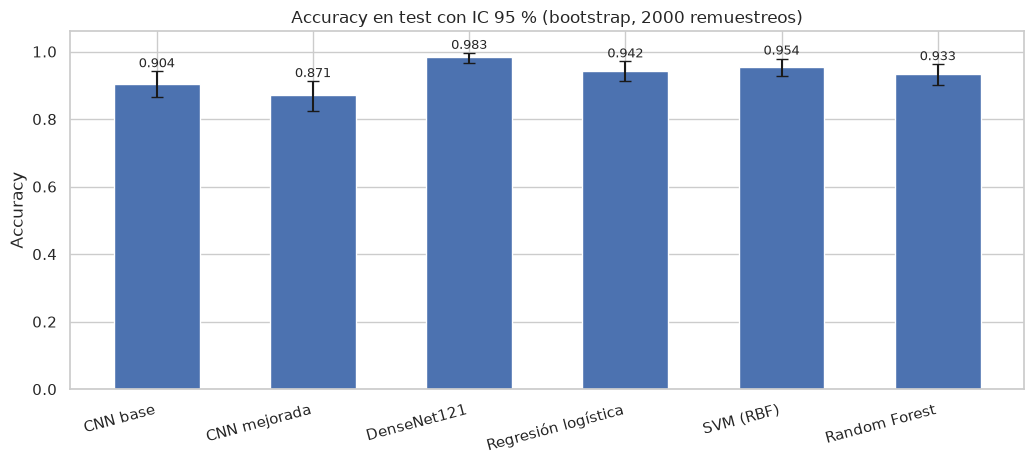

In [2]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: figura omitida.")
else:
    fig, ax = plt.subplots(figsize=(10.5, 4.8))
    positions = np.arange(len(results))
    ax.bar(
        positions,
        results["accuracy"],
        0.55,
        yerr=[
            results["accuracy"] - results["accuracy_low"],
            results["accuracy_high"] - results["accuracy"],
        ],
        capsize=4,
    )
    for position, (_, row) in enumerate(results.iterrows()):
        ax.text(
            position,
            row["accuracy_high"] + 0.012,
            f"{row['accuracy']:.3f}",
            ha="center",
            fontsize=9,
        )
    ax.set_xticks(positions, results["model"], rotation=15, ha="right")
    ax.set_ylim(0, 1.06)
    ax.set_ylabel("Accuracy")
    ax.set_title("Accuracy en test con IC 95 % (bootstrap, 2000 remuestreos)")
    fig.tight_layout()
    fig.savefig(comparison_dir / "barras_accuracy_ic95.png", dpi=150, bbox_inches="tight")
    plt.show()

## Figura 2: matrices de confusión

Una matriz de confusión normalizada por fila para cada modelo (de nuevo el
mismo test): dónde se concentra el error y qué clases se confunden entre sí.

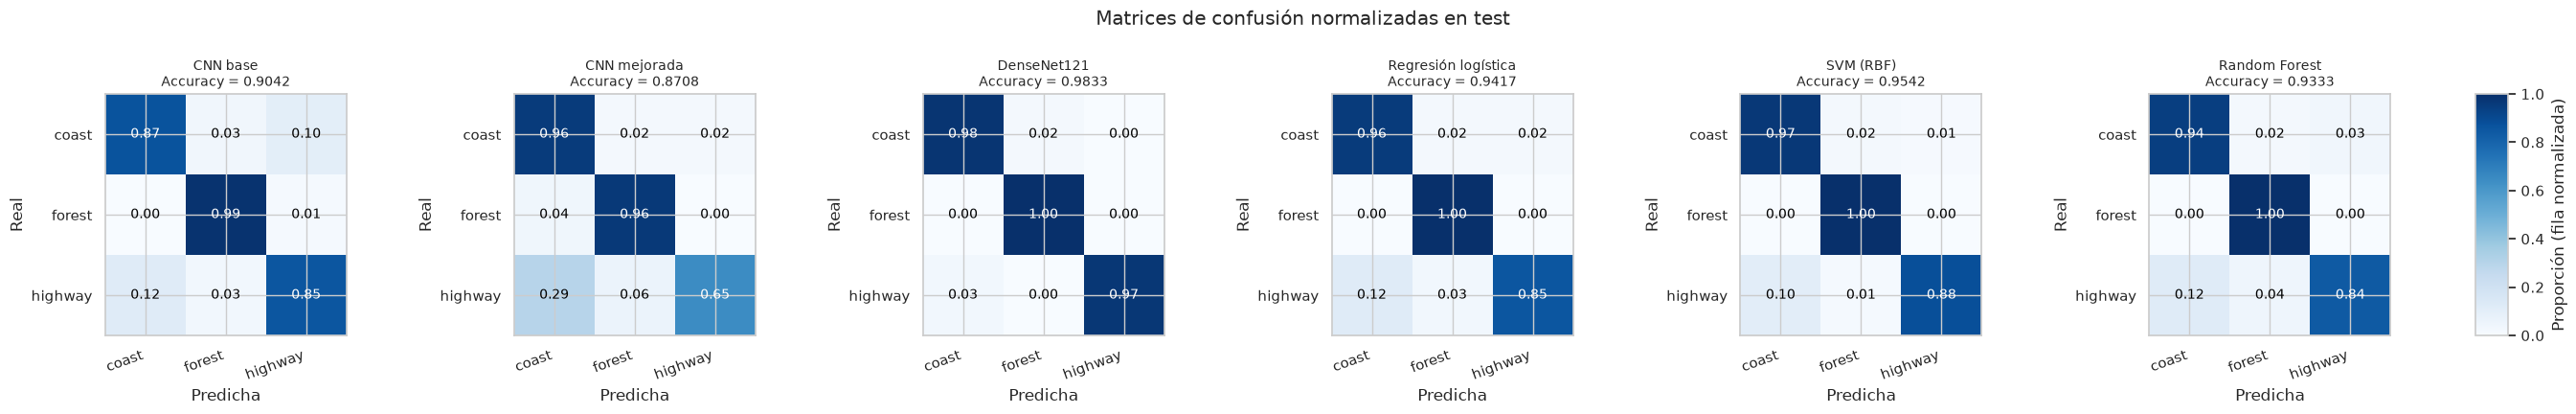

In [3]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: figura omitida.")
else:
    fig, axes = plt.subplots(1, len(results), figsize=(4.8 * len(results), 4.2))
    for ax, (_, row) in zip(np.atleast_1d(axes), results.iterrows()):
        metrics = cs.load_metrics(row["folder"])
        matrix = np.asarray(metrics["confusion_matrix"], dtype=float)
        matrix = matrix / matrix.sum(axis=1, keepdims=True)
        image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(len(cs.CLASSES)), cs.CLASSES, rotation=20, ha="right")
        ax.set_yticks(range(len(cs.CLASSES)), cs.CLASSES)
        for row_index in range(len(cs.CLASSES)):
            for column_index in range(len(cs.CLASSES)):
                value = matrix[row_index, column_index]
                ax.text(
                    column_index,
                    row_index,
                    f"{value:.2f}",
                    ha="center",
                    va="center",
                    color="white" if value > 0.5 else "black",
                    fontsize=10,
                )
        ax.set_title(f"{row['model']}\nAccuracy = {row['accuracy']:.4f}", fontsize=10)
        ax.set_xlabel("Predicha")
        ax.set_ylabel("Real")

    fig.subplots_adjust(left=0.06, right=0.90, bottom=0.22, top=0.82, wspace=0.50)
    colorbar_ax = fig.add_axes([0.925, 0.22, 0.012, 0.60])
    fig.colorbar(image, cax=colorbar_ax, label="Proporción (fila normalizada)")
    fig.suptitle("Matrices de confusión normalizadas en test", y=1.03)
    fig.savefig(comparison_dir / "matrices_confusion.png", dpi=150, bbox_inches="tight")
    plt.show()

## Figura 3: curvas de aprendizaje

Accuracy y pérdida (train y validación) por época de los modelos con épocas.
Los modelos de **machine learning no tienen curvas** (no hay épocas ni
`history.csv`), así que se omiten y se anota la omisión.

[nota] Sin curvas de aprendizaje (modelos sin épocas): Regresión logística, SVM (RBF), Random Forest


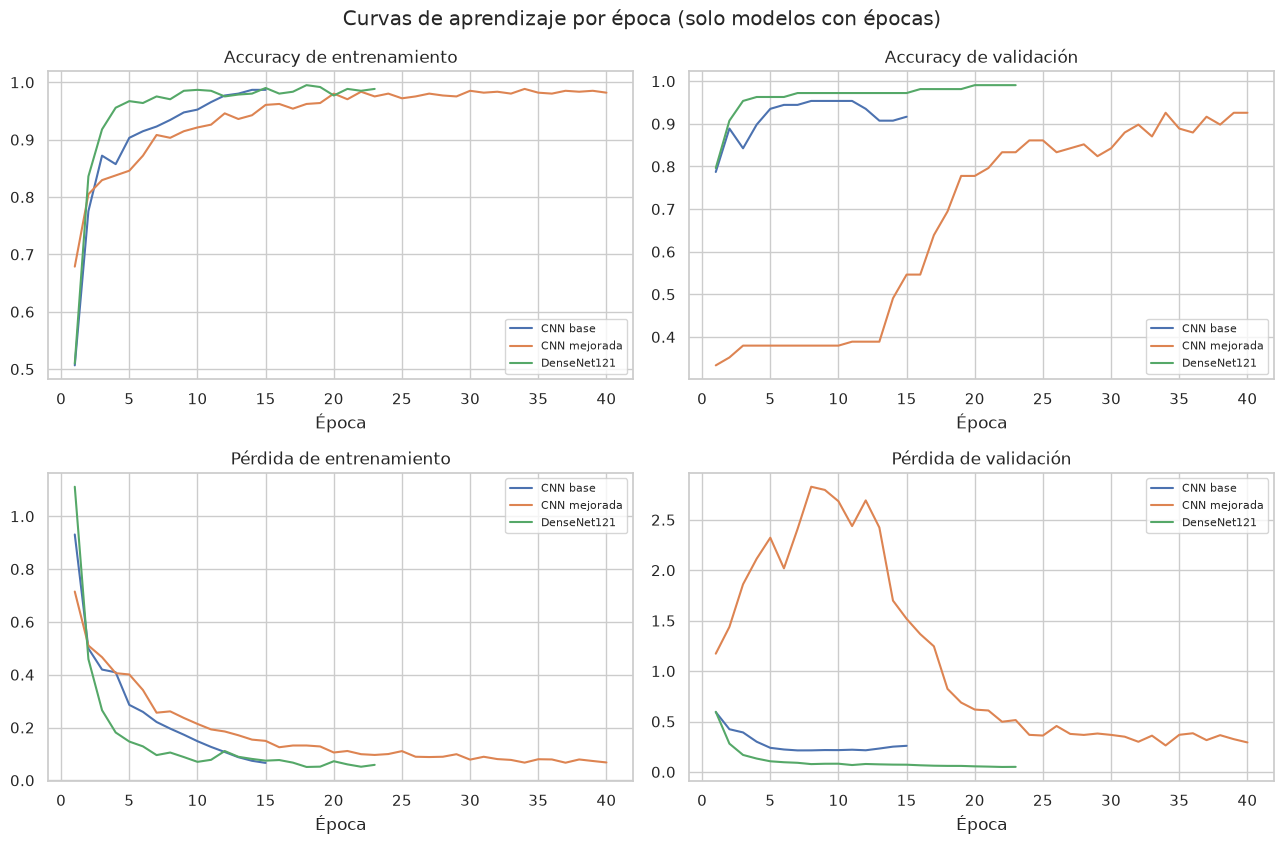

In [4]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: figura omitida.")
else:
    fig, axes = plt.subplots(2, 2, figsize=(13, 8.6))
    curves = [
        ("accuracy", "Accuracy de entrenamiento", axes[0, 0]),
        ("val_accuracy", "Accuracy de validación", axes[0, 1]),
        ("loss", "Pérdida de entrenamiento", axes[1, 0]),
        ("val_loss", "Pérdida de validación", axes[1, 1]),
    ]

    with_curves = []
    for _, row in results.iterrows():
        history = cs.load_history(row["folder"])
        if history is None:
            continue
        with_curves.append(row["model"])
        for column, _, ax in curves:
            ax.plot(history.index, history[column], label=row["model"])

    for column, title, ax in curves:
        ax.set_xlabel("Época")
        ax.set_title(title)
        ax.legend(fontsize=8)

    without_curves = [name for name in results["model"] if name not in with_curves]
    if without_curves:
        print(
            "[nota] Sin curvas de aprendizaje (modelos sin épocas): "
            + ", ".join(without_curves)
        )
    fig.suptitle("Curvas de aprendizaje por época (solo modelos con épocas)")
    fig.tight_layout()
    fig.savefig(comparison_dir / "curvas_aprendizaje.png", dpi=150, bbox_inches="tight")
    plt.show()

## Figura 4: F1 por clase

Heatmap del F1-score de cada clase para cada modelo: revela si algún modelo
paga su accuracy global en una clase concreta.

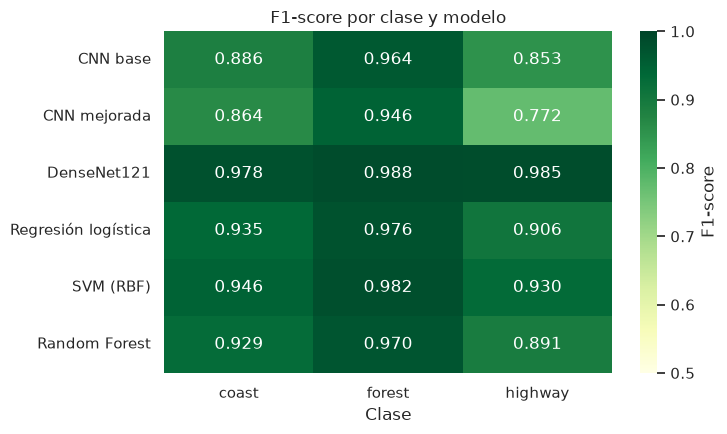

In [5]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: figura omitida.")
else:
    f1_columns = [f"f1_{class_name}" for class_name in cs.CLASSES]
    f1_matrix = results.set_index("model")[f1_columns]
    f1_matrix.columns = cs.CLASSES

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    sns.heatmap(
        f1_matrix,
        annot=True,
        fmt=".3f",
        cmap="YlGn",
        vmin=0.5,
        vmax=1,
        ax=ax,
        cbar_kws={"label": "F1-score"},
    )
    ax.set_title("F1-score por clase y modelo")
    ax.set_xlabel("Clase")
    ax.set_ylabel("")
    fig.tight_layout()
    fig.savefig(comparison_dir / "heatmap_f1_por_clase.png", dpi=150, bbox_inches="tight")
    plt.show()
    f1_matrix.round(4)

## Validación estadística: McNemar

Test exacto de McNemar sobre las predicciones emparejadas del mismo test para
las comparaciones que pide el reto: base vs mejorada, mejorada vs DenseNet121,
base vs DenseNet121, DenseNet121 vs Swin, CNN mejorada vs Swin y el mejor
modelo de machine learning contra el mejor modelo de aprendizaje profundo.
La tabla se guarda también como `resultados/comparacion/mcnemar_pvalues.csv`
(junto a `model_summary.csv`).

In [6]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: tabla omitida.")
else:
    def model_of(folder):
        return results.loc[results["folder"] == folder, "model"].iloc[0]

    best_ml_row = (
        results[results["folder"].str.startswith("ml/")]
        .sort_values("accuracy", ascending=False)
        .iloc[0]
    )
    best_dl_row = (
        results[~results["folder"].str.startswith("ml/")]
        .sort_values("accuracy", ascending=False)
        .iloc[0]
    )

    comparison_pairs = [
        ("cnn/base", "cnn/mejorada"),
        ("cnn/mejorada", "densenet"),
        ("cnn/base", "densenet"),
        ("densenet", "swin"),
        ("cnn/mejorada", "swin"),
        (best_ml_row["folder"], best_dl_row["folder"]),
    ]
    available = set(results["folder"])
    comparison_pairs = [
        (folder_a, folder_b)
        for folder_a, folder_b in comparison_pairs
        if folder_a in available and folder_b in available
    ]

    rows = []
    for folder_a, folder_b in comparison_pairs:
        name_a, name_b = model_of(folder_a), model_of(folder_b)
        frame_a = predictions.get(name_a)
        frame_b = predictions.get(name_b)
        if frame_a is None or frame_b is None:
            p_value = np.nan
        else:
            p_value = cs.mcnemar_pvalue(
                frame_a["true_class"],
                frame_a["predicted_class"],
                frame_b["predicted_class"],
            )
        rows.append({"modelo_a": name_a, "modelo_b": name_b, "p_valor": p_value})

    mcnemar_table = pd.DataFrame(rows)
    mcnemar_table.to_csv(
        comparison_dir / "mcnemar_pvalues.csv",
        float_format="%.4f",
        index=False,
    )
    print(f"Mejor modelo clásico: {best_ml_row['model']} ({best_ml_row['accuracy']:.2%}).")
    print(f"Mejor modelo de deep learning: {best_dl_row['model']} ({best_dl_row['accuracy']:.2%}).")
mcnemar_table.round(4) if HAS_RESULTS else None

Mejor modelo clásico: SVM (RBF) (95.42%).
Mejor modelo de deep learning: DenseNet121 (98.33%).


,modelo_a,modelo_b,p_valor
0,CNN base,CNN mejorada,0.2005
1,CNN mejorada,DenseNet121,0.0000
2,CNN base,DenseNet121,0.0001
3,SVM (RBF),DenseNet121,0.0654


## El Transformer Swin: ¿arquitectura o preentrenamiento?

El Swin de `resultados/swin/` se entrena **desde cero**, así que frente a la
DenseNet121 (preentrenada en ImageNet) permite separar dos efectos que en el
reto van siempre juntos:

* **Arquitectura**: CNN mejorada vs Swin compara convolución y atención con
  el mismo punto de partida (las dos se entrenan desde cero, sin ImageNet).
* **Preentrenamiento**: DenseNet121 vs Swin suma al cambio de arquitectura el
  efecto de arrancar de filtros ya aprendidos en ImageNet.

Las tres preguntas de la entrega se responden en la celda siguiente **leyendo
los números** de `resultados/` (accuracy, IC 95 % por bootstrap y el McNemar
de la sección anterior):

1. ¿Es el Transformer competitivo con DenseNet121?
2. ¿Cuánto del hueco es arquitectura y cuánto preentrenamiento?
3. ¿Es la diferencia significativa según McNemar o queda dentro del IC?


In [7]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: análisis del Transformer omitido.")
else:
    swin_row = results[results["folder"] == "swin"]
    densenet_row = results[results["folder"] == "densenet"]
    if swin_row.empty or densenet_row.empty:
        print(
            "[aviso] Faltan los resultados del Swin o de la DenseNet121 (ejecuta "
            "antes ScenesSWIN.ipynb y ScenesDenseNet.ipynb): análisis omitido."
        )
    else:
        swin_row = swin_row.iloc[0]
        densenet_row = densenet_row.iloc[0]
        improved_acc = results.loc[results["folder"] == "cnn/mejorada", "accuracy"].iloc[0]
        gap_densenet = 100 * (densenet_row["accuracy"] - swin_row["accuracy"])
        gap_architecture = 100 * (swin_row["accuracy"] - improved_acc)
        intervals_overlap = (
            swin_row["accuracy_high"] >= densenet_row["accuracy_low"]
            and densenet_row["accuracy_high"] >= swin_row["accuracy_low"]
        )

        def pvalue_of(folder_a, folder_b):
            matched = mcnemar_table[
                (mcnemar_table["modelo_a"] == model_of(folder_a))
                & (mcnemar_table["modelo_b"] == model_of(folder_b))
            ]
            return np.nan if matched.empty else matched["p_valor"].iloc[0]

        p_densenet_swin = pvalue_of("densenet", "swin")
        p_improved_swin = pvalue_of("cnn/mejorada", "swin")

        print("El Transformer Swin frente a DenseNet121 (números de resultados/)")
        print("=" * 78)
        print(
            f"1. ¿Competitivo? Swin (desde cero): {swin_row['accuracy']:.2%} "
            f"(IC 95 % {swin_row['accuracy_low']:.2%}–{swin_row['accuracy_high']:.2%}); "
            f"DenseNet121 (ImageNet): {densenet_row['accuracy']:.2%} "
            f"(IC 95 % {densenet_row['accuracy_low']:.2%}–{densenet_row['accuracy_high']:.2%}). "
            f"Hueco: {gap_densenet:+.1f} puntos."
        )
        print(
            f"2. Arquitectura o preentrenamiento: frente a la CNN mejorada "
            f"({improved_acc:.2%}, también desde cero), el Swin "
            f"({swin_row['accuracy']:.2%}) aporta {gap_architecture:+.1f} puntos "
            f"atribuibles a la arquitectura (atención vs convolución). El hueco "
            f"restante hasta DenseNet121 ({gap_densenet:+.1f} puntos) no es solo "
            f"arquitectura: mezcla atención y el preentrenamiento en ImageNet "
            f"(~1,2 M de imágenes frente a las 961 del reto), así que no se "
            f"puede atribuir en solitario a ninguno de los dos efectos."
        )
        if pd.isna(p_densenet_swin):
            print("3. Significancia: no disponible (faltan predicciones).")
        else:
            verdict = (
                "diferencia estadísticamente significativa"
                if p_densenet_swin < 0.05
                else "diferencia dentro del ruido del muestreo"
            )
            print(
                f"3. Significancia: McNemar DenseNet121 vs Swin: "
                f"p = {p_densenet_swin:.4f} → {verdict}."
            )
            if not pd.isna(p_improved_swin):
                verdict_improved = (
                    "significativa"
                    if p_improved_swin < 0.05
                    else "no significativa"
                )
                print(
                    f"   CNN mejorada vs Swin: p = {p_improved_swin:.4f} → "
                    f"diferencia {verdict_improved}."
                )
            print(
                "   En el bootstrap, los IC 95 % de los dos modelos "
                + ("solapan." if intervals_overlap else "no solapan.")
            )

[aviso] Faltan los resultados del Swin o de la DenseNet121 (ejecuta antes ScenesSWIN.ipynb y ScenesDenseNet.ipynb): análisis omitido.


## Conclusiones

Las conclusiones se **generan en la celda siguiente** a partir de los
artefactos de `resultados/` (`metrics.json`, `predictions.csv`,
`split.json`): ninguna cifra está escrita a mano en este cuaderno, de modo que
si un modelo se reentrena, las conclusiones se recalculan solas. El esquema es
el que pide el enunciado: quién gana, si la diferencia es estadísticamente
significativa o ruido del intervalo de confianza, cuánto aporta cada cambio
(más filtros, BatchNorm, augmentación, GAP, conectividad densa + transferencia
de ImageNet, atención por ventanas desde cero) y qué limitación impone el
dataset.

In [8]:
if not HAS_RESULTS:
    print("[aviso] Sin resultados entrenados: no hay conclusiones que generar todavía.")
else:
    ranked = results.sort_values("accuracy", ascending=False).reset_index(drop=True)
    best = ranked.iloc[0]
    second = ranked.iloc[1]
    best_ml_row = (
        results[results["folder"].str.startswith("ml/")]
        .sort_values("accuracy", ascending=False)
        .iloc[0]
    )
    best_dl_row = (
        results[~results["folder"].str.startswith("ml/")]
        .sort_values("accuracy", ascending=False)
        .iloc[0]
    )

    def accuracy_of(folder):
        return results.loc[results["folder"] == folder, "accuracy"].iloc[0]

    def format_count(value):
        if value is None or pd.isna(value):
            return "n/d"
        return f"{int(value):,}"

    delta_improved = 100 * (accuracy_of("cnn/mejorada") - accuracy_of("cnn/base"))
    delta_densenet = 100 * (accuracy_of("densenet") - accuracy_of("cnn/mejorada"))
    delta_transfer = 100 * (accuracy_of("densenet") - accuracy_of("cnn/base"))
    delta_ml_dl = 100 * (best_dl_row["accuracy"] - best_ml_row["accuracy"])
    ci_widths = 100 * (results["accuracy_high"] - results["accuracy_low"])
    n_total = split_meta.get("n_total", "n/d")
    n_test = split_meta.get("n_test", "n/d")

    if pd.isna(best["accuracy_low"]):
        interval = "IC no disponible"
    else:
        interval = (
            f"IC 95 % {best['accuracy_low']:.2%}–{best['accuracy_high']:.2%}"
        )

    print("Conclusiones (generadas a partir de resultados/)")
    print("=" * 78)
    print(
        f"1. Ganador. {best['model']} es el mejor modelo en test: accuracy "
        f"{best['accuracy']:.2%} ({interval}), F1 macro {best['f1_macro']:.2%}, "
        f"kappa {best['cohen_kappa']:.3f} y {format_count(best['parameters'])} "
        f"parámetros. Le sigue {second['model']} con {second['accuracy']:.2%}."
    )
    print("2. Significancia (test exacto de McNemar, α = 0,05):")
    for _, row in mcnemar_table.iterrows():
        if pd.isna(row["p_valor"]):
            print(
                f"   - {row['modelo_a']} vs {row['modelo_b']}: no disponible "
                "(faltan predicciones)."
            )
        else:
            verdict = (
                "diferencia significativa"
                if row["p_valor"] < 0.05
                else "diferencia dentro del ruido"
            )
            print(
                f"   - {row['modelo_a']} vs {row['modelo_b']}: "
                f"p = {row['p_valor']:.4f} → {verdict}."
            )
    print("3. Contribución de cada cambio (puntos de accuracy sobre el mismo test):")
    print(
        f"   - CNN base → CNN mejorada (más filtros, BatchNorm, GAP, Dropout, "
        f"augmentación, class_weight): {delta_improved:+.1f} puntos."
    )
    print(
        f"   - CNN mejorada → DenseNet121 (conectividad densa + transferencia de "
        f"ImageNet): {delta_densenet:+.1f} puntos."
    )
    print(
        f"   - CNN base → DenseNet121 (todo lo anterior junto): "
        f"{delta_transfer:+.1f} puntos."
    )
    if "swin" in set(results["folder"]):
        print(
            f"   - CNN mejorada → Swin (atención por ventanas vs convolución, "
            f"ambas desde cero): "
            f"{100 * (accuracy_of('swin') - accuracy_of('cnn/mejorada')):+.1f} puntos."
        )
        print(
            f"   - Swin → DenseNet121 (cambio de arquitectura + preentrenamiento "
            f"de ImageNet): "
            f"{100 * (accuracy_of('densenet') - accuracy_of('swin')):+.1f} puntos."
        )
    print(
        f"   - Mejor modelo clásico ({best_ml_row['model']}, "
        f"{best_ml_row['accuracy']:.2%}) vs mejor modelo de deep learning "
        f"({best_dl_row['model']}, {best_dl_row['accuracy']:.2%}): "
        f"{delta_ml_dl:+.1f} puntos."
    )
    print(
        f"4. Limitación del dataset. El dataset tiene {n_total} imágenes en "
        f"{len(cs.CLASSES)} clases y solo {n_test} imágenes de test. El IC 95 % "
        f"más ancho de la figura 1 mide {ci_widths.max():.1f} puntos "
        f"porcentuales, de modo que diferencias de pocos puntos entre modelos "
        f"quedan dentro del ruido del muestreo: para decidir si son reales hay "
        f"que mirar el McNemar de la sección anterior."
    )
    print(
        f"5. Coste. {best['model']} tardó {best['training_seconds']:.0f} s en "
        f"entrenar y {best['inference_ms_per_image']:.1f} ms/imagen en inferir. "
        f"Los modelos de machine learning no tienen épocas ni un conteo de "
        f"parámetros comparable (así se registra en sus metrics.json) y son la "
        f"referencia de coste bajo."
    )
    print(
        "6. IA generativa (Transformer). El Swin Transformer entrenado desde "
        "cero se incorpora en esta entrega (resultados/swin/); al no usar "
        "ImageNet, su comparación con DenseNet121 separa arquitectura y "
        "preentrenamiento, como detalla la sección «El Transformer Swin»."
    )

Conclusiones (generadas a partir de resultados/)
1. Ganador. DenseNet121 es el mejor modelo en test: accuracy 98.33% (IC 95 % 96.67%–99.58%), F1 macro 98.36%, kappa 0.975 y 7,040,579 parámetros. Le sigue SVM (RBF) con 95.42%.
2. Significancia (test exacto de McNemar, α = 0,05):
   - CNN base vs CNN mejorada: p = 0.2005 → diferencia dentro del ruido.
   - CNN mejorada vs DenseNet121: p = 0.0000 → diferencia significativa.
   - CNN base vs DenseNet121: p = 0.0001 → diferencia significativa.
   - SVM (RBF) vs DenseNet121: p = 0.0654 → diferencia dentro del ruido.
3. Contribución de cada cambio (puntos de accuracy sobre el mismo test):
   - CNN base → CNN mejorada (más filtros, BatchNorm, GAP, Dropout, augmentación, class_weight): -3.3 puntos.
   - CNN mejorada → DenseNet121 (conectividad densa + transferencia de ImageNet): +11.2 puntos.
   - CNN base → DenseNet121 (todo lo anterior junto): +7.9 puntos.
   - Mejor modelo clásico (SVM (RBF), 95.42%) vs mejor modelo de deep learning (DenseNe

## Notas finales

* Toda la evidencia de esta comparación queda en `resultados/comparacion/`:
  `model_summary.csv`, `mcnemar_pvalues.csv` y las cuatro figuras
  (`barras_accuracy_ic95.png`, `matrices_confusion.png`,
  `curvas_aprendizaje.png`, `heatmap_f1_por_clase.png`).
* Con ~240 imágenes de test, el IC 95 % de la accuracy es intrínsecamente
  ancho; por eso el reto pide además el bootstrap y el McNemar antes de
  declarar un ganador.
* Los descriptores HSV+HOG son la línea base clásica; la comparación directa
  con aprendizaje profundo y con IA generativa queda recogida en las
  conclusiones generadas y en la sección «El Transformer Swin».